<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_WEEK_13_1-Kaggle4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://www.kaggle.com/code/saumandas/neural-networks-in-tensorflow-with-titanic

위 캐글을 필사

# **Neural Networks in Tensorflow with Titanic**

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

for dirname, _, filenames in os.walk('/content/drive/MyDrive/ESAA_OB/OB_data/Kaggle4t'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 5GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## Reading the Data

In [2]:
train_df = pd.read_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Kaggle4/train.csv')

In [3]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


.info를 사용하면
- 데이터셋의 전체적인 구조를 빠르게 파악할 수 있음
- 각 변수(열)의 이름과 데이터 개수를 확인할 수 있으며, 여기서는 Age, Cabin, Embarked 열에 결측치(누락된 값)가 존재한다는 것을 알 수 있음
- 또한 데이터의 한 행을 직접 살펴보면 어떤 특성(feature)들이 모델 학습에 유용할지 더 쉽게 판단할 수 있음

In [4]:
train_df.loc[0]

,0
PassengerId,1
Survived,0
Pclass,3
Name,"Braund, Mr. Owen Harris"
Sex,male
Age,22.0
SibSp,1
Parch,0
Ticket,A/5 21171
Fare,7.25


모델 학습을 위해 어떤 특성을 사용할지 검토해 보면,

- Name은 승객 이름일 뿐이므로 생존 여부를 예측하는 데 큰 도움이 되지 않아 제거
- Ticket도 유용성이 낮으며, 값이 숫자와 문자가 섞여 있어 사용할 경우 범주형 변수로 처리해야 함
- PassengerId는 단순 식별번호라서 예측에 도움이 되지 않으므로 제거
- Cabin은 결측치가 너무 많아 분석에서 제외

In [5]:
#Drop Name and Ticket

train_df.drop(['Name', 'Ticket', 'PassengerId', 'Cabin'], axis=1, inplace=True)
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


train_df를 X와 y로 분리

In [6]:
X = train_df.drop('Survived', axis=1, inplace=False)
y = train_df['Survived']

print(f'Input features shape: {X.shape}')
print(f'Labels shape: {y.shape}')

Input features shape: (891, 7)
Labels shape: (891,)


### Data Analysis

In [7]:
#Import visualization libraries

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

모델이 예측해야 하는 대상인 생존 여부(Survived) 의 분포를 확인하여, 특정 클래스(생존 또는 사망)에 데이터가 지나치게 치우쳐 있는지 알아보자

Text(0, 0.5, 'Number of Passengers')

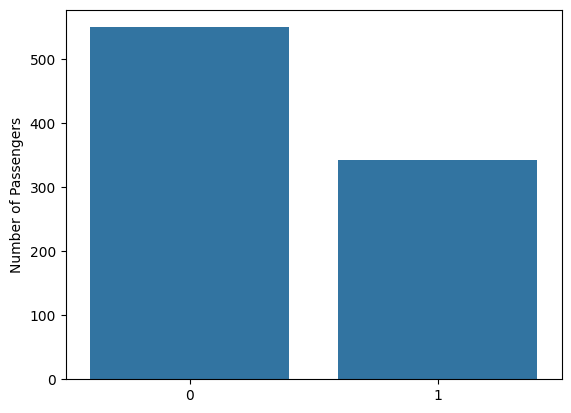

In [8]:
sns.barplot(x = y.unique(), y = y.value_counts())
plt.ylabel('Number of Passengers')

타이타닉 데이터셋은 클래스 불균형이 심각하지 않기 때문에 비교적 무난하게 모델을 학습시킬 수 있음

그다음 단계로는 각 변수에 결측치가 얼마나 있는지 확인하여 전처리 방법을 결정

   Pclass  Sex  Age  SibSp  Parch  Fare  Embarked
0     891  891  714    891    891   891       889


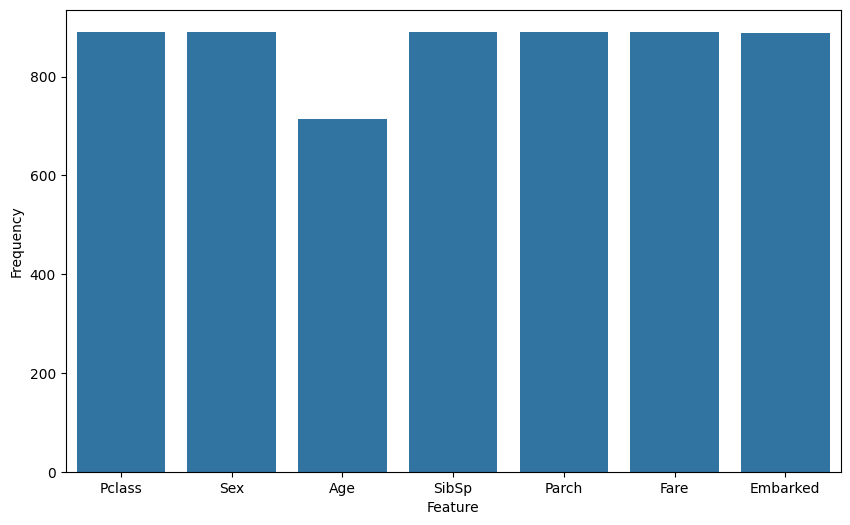

In [9]:
frequencies = X.count()

freq_df = pd.DataFrame([frequencies], columns=X.columns)
print(freq_df.head())

plt.figure(figsize=(10, 6))
sns.barplot(x=X.columns, y = frequencies)
plt.ylabel('Frequency')
plt.xlabel('Feature')
plt.show()

결측치 현황을 살펴보면 Age 변수에 결측치가 많이 존재하고, Embarked 변수에도 2개의 결측치가 있음

Scikit-Learn은 SimpleImputer를 통해 이러한 결측값을 대체(impute)할 수 있는 간단하고 편리한 방법을 제공



### Imputing and One-Hot Encoding

- 대체(Imputing)란 결측값을 처리하는 과정을 의미

- 결측치를 처리하는 가장 단순한 방법은 해당 행들을 모두 삭제하는 것이지만, 그렇게 하면 원래 891개의 학습 데이터 중 714개만 남게 되어 중요한 정보를 많이 잃게 됨

- 그래서 Scikit-Learn의 SimpleImputer 를 사용하여 결측치를 적절한 값(예: 평균값, 최빈값 등)으로 채워 넣고, 가능한 한 많은 데이터를 유지한 채 모델을 학습시키는 것

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

'''
The following pipeline is only for numerical features:
1. Fill in Missing Values with Median value of existing numbers
2. Scale all the numbers to be in between 0 and 1
'''

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ('std_scaler', StandardScaler())
])

'''
The following pipeline is only for categorical features:
1. Fill in Missing Values with Most Frequent value from existing data
2. One-hot encode (https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
'''

cat_pipeline = Pipeline([
    ('cat_imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder())
])

In [11]:
#Combine Pipelines

from sklearn.compose import ColumnTransformer

num_attribs = ['Age', 'SibSp', 'Parch', 'Fare']
cat_attribs = ['Pclass', 'Sex', 'Embarked']

full_pipeline = ColumnTransformer([("num", num_pipeline, num_attribs),
                                   ("cat", cat_pipeline, cat_attribs)])
X = full_pipeline.fit_transform(X)
X.shape

(891, 12)

결측치 처리와 불필요한 변수 제거 등 데이터 전처리가 완료되었음

이제 모델 학습을 위해 데이터를 학습용 데이터와 성능 평가용 데이터로 분리
- 이를 위해 scikit-learn의 train_test_split() 함수를 사용

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

### Neural Network

데이터 전처리가 모두 끝났으므로 TensorFlow를 이용해 실제 신경망 모델 구축

이번 예제에서는 비교적 단순한 구조의 신경망을 사용
- 입력층(Input Layer)
- 은닉층 1 (Hidden Layer)
- 은닉층 2 (Hidden Layer)
- 출력층(Output Layer, 뉴런 1개)

타이타닉 문제는 "생존(1) 또는 사망(0)" 을 예측하는 문제이므로, 출력은 하나의 값만 있으면 됨. 따라서 출력층에 뉴런을 1개만 둠

또한 신경망이 어떤 원리로 학습되는지, 특히 역전파 알고리즘의 동작 방식을 깊이 이해하고 싶다면 저자가 작성한 별도의 "Neural Networks from Scratch" 튜토리얼을 참고

In [13]:
#Import necessary libraries

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers as L

TensorFlow에서는 몇 줄의 코드만으로도 신경망을 구축할 수 있음

1. Sequential 모델 정의

        model = Sequential()

2. 입력층(Input Layer) 추가

        model.add(L.InputLayer(input_shape=...))

    → 선택 사항(Optional)

3. 완전 연결층(Fully Connected Layer, Dense Layer) 추가

        model.add(L.Dense(...))

4. 모델 컴파일(Compile Model)

5. 콜백(Callbacks) 설정 (필요한 경우)

6. 모델 학습(Train Model)

물론 더 복잡한 모델도 만들 수 있지만, 이 데이터셋은 TensorFlow의 기본 API만 사용해도 충분히 해결할 수 있음

In [14]:
#Step 1
model = Sequential(name='titanic_model')

#Step 2
model.add(L.InputLayer(input_shape=(12,))) # necessary to use model.summary()

#Step 3
model.add(L.Dense(512, activation='relu'))
model.add(L.Dense(1024, activation='relu'))
model.add(L.Dropout(0.4)) #prevents overfitting by setting 40% of nuerons to 0
model.add(L.Dense(512, activation='relu'))
model.add(L.Dropout(0.4))
model.add(L.Dense(128, activation='relu'))
model.add(L.Dense(64, activation='relu'))
model.add(L.Dense(64, activation='relu'))
model.add(L.Dense(1, activation='sigmoid')) # output layer, use sigmoid for binary

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "titanic_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,134,913 (4.33 MB)

 Trainable params: 1,134,913 (4.33 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
#Step 4
model.compile(loss='binary_crossentropy', optimizer=keras.optimizers.Adam(0.0001), metrics=['accuracy'])

In [16]:
'''
This custom callback stops training once the validation accuracy reaches 83%.
There are several callbacks already implemented by keras.
https://www.tensorflow.org/api_docs/python/tf/keras/callbacks

'''

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if(logs.get('val_accuracy')>0.83):
            print("\nReached 83% accuracy so cancelling training!")
            self.model.stop_training = True


#Step 6
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    batch_size=8,
                    callbacks=[myCallback()],
                    epochs=50)

Epoch 1/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.6559 - loss: 0.6154 - val_accuracy: 0.7654 - val_loss: 0.5218
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8048 - loss: 0.4893 - val_accuracy: 0.7933 - val_loss: 0.4511
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8160 - loss: 0.4529 - val_accuracy: 0.8045 - val_loss: 0.4322
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8258 - loss: 0.4210 - val_accuracy: 0.8101 - val_loss: 0.4385
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8132 - loss: 0.4321 - val_accuracy: 0.8212 - val_loss: 0.4279
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.8301 - loss: 0.4141 - val_accuracy: 0.8212 - val_loss: 0.4303
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8357 - loss: 0.4006 - val_accuracy: 0.8156 - val_loss: 0.4437
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8272 - loss: 0.3893 - val_accuracy: 0.8268 - v

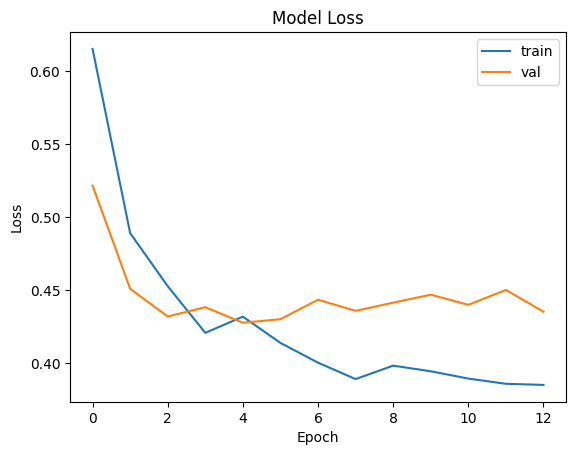

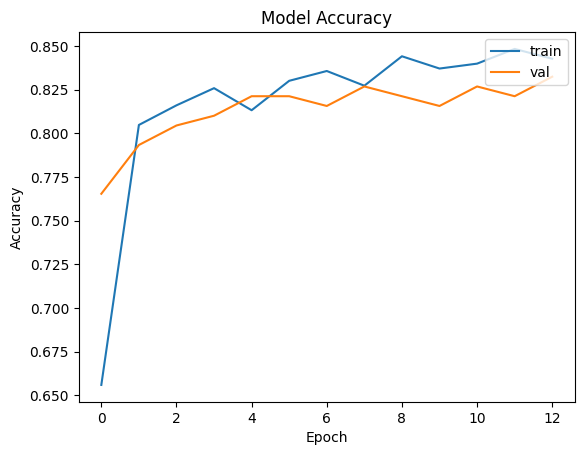

In [17]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(['train', 'val'], loc='upper right')
plt.show()

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['train', 'val'], loc='upper right')
plt.show()

위의 그래프를 보면

훈련 손실(train loss)은 지속적으로 감소하는 반면,

검증 손실(validation loss)은 처음 몇 번의 에포크(epoch)가 지난 후부터 증가하기 시작하는 것을 확인할 수 있음

이는 과적합(overfitting)의 전형적인 징후

## Prepare the Test Data

다시 한 번, 학습 데이터(train data)에서 했던 것과 동일하게 불필요한 데이터를 제거해야 함

그다음에는 이전에 사용했던 것과 동일한 파이프라인(pipeline) 을 이용하여 데이터를 변환(transform)해야 함

그 후, 모델의 예측값(prediction)이 0.5보다 크면 해당 승객이 생존한 것으로 판단

마지막으로, 제출 파일(submission)을 생성할 수 있음

In [18]:
test_df = pd.read_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Kaggle4/test.csv')
test_df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
test_df

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,34.5,0,0,7.8292,Q
1,3,female,47.0,1,0,7.0000,S
2,2,male,62.0,0,0,9.6875,Q
3,3,male,27.0,0,0,8.6625,S
4,3,female,22.0,1,1,12.2875,S
...,...,...,...,...,...,...,...
413,3,male,NaN,0,0,8.0500,S
414,1,female,39.0,0,0,108.9000,C
415,3,male,38.5,0,0,7.2500,S
416,3,male,NaN,0,0,8.0500,S


In [19]:
test_prepared = full_pipeline.transform(test_df)
test_prepared.shape

(418, 12)

In [20]:
preds = model.predict(test_prepared)
preds[:5]

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


array([[0.08028616],
       [0.32664496],
       [0.03015877],
       [0.10762011],
       [0.39094383]], dtype=float32)

In [21]:
submission = pd.read_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Kaggle4/gender_submission.csv')
submission['Survived'] = [0 if pred < 0.5 else 1 for pred in preds]
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [22]:
from IPython.display import FileLink


submission.to_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Kaggle4/submission.csv',index=False)
FileLink(r'submission.csv')

/content/submission.csv